In [1]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("student_exam_outcomes.csv")

In [3]:
df.head()

,study_hours_per_day,attendance_percent,assignment_completion_percent,sleep_hours,tutoring,previous_exam_score,passed
0,4.2,89.4,66,6.5,Yes,32.7,1
1,0.2,66.1,73,7.0,Yes,69.8,0
2,5.5,84.8,37,7.4,No,35.6,1
3,5.6,75.7,46,6.7,No,46.6,1
4,0.7,96.7,80,6.1,Yes,81.9,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   study_hours_per_day            400 non-null    float64
 1   attendance_percent             400 non-null    float64
 2   assignment_completion_percent  400 non-null    int64  
 3   sleep_hours                    400 non-null    float64
 4   tutoring                       400 non-null    str    
 5   previous_exam_score            400 non-null    float64
 6   passed                         400 non-null    int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 22.0 KB


In [5]:
# le = LabelEncoder()
# df["tutoring"] = le.fit_transform(df["tutoring"])
categorical_col = df.select_dtypes(exclude="number").columns
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_encoded = encoder.fit_transform(df[categorical_col])

In [6]:
df.head()

,study_hours_per_day,attendance_percent,assignment_completion_percent,sleep_hours,tutoring,previous_exam_score,passed
0,4.2,89.4,66,6.5,Yes,32.7,1
1,0.2,66.1,73,7.0,Yes,69.8,0
2,5.5,84.8,37,7.4,No,35.6,1
3,5.6,75.7,46,6.7,No,46.6,1
4,0.7,96.7,80,6.1,Yes,81.9,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   study_hours_per_day            400 non-null    float64
 1   attendance_percent             400 non-null    float64
 2   assignment_completion_percent  400 non-null    int64  
 3   sleep_hours                    400 non-null    float64
 4   tutoring                       400 non-null    str    
 5   previous_exam_score            400 non-null    float64
 6   passed                         400 non-null    int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 22.0 KB


In [8]:
df.nunique()

study_hours_per_day               80
attendance_percent               284
assignment_completion_percent     81
sleep_hours                       56
tutoring                           2
previous_exam_score              315
passed                             2
dtype: int64

In [9]:
x = df.drop(["passed", "tutoring"], axis=1)
X = np.hstack([x, X_encoded])

In [10]:
model = DBSCAN(eps=0.5, min_samples=5)
label = model.fit_predict(X)

In [11]:
mask = label != 1

In [12]:
if(len(set(label[mask]))) >= 2:
    print("Silhouette_score: ", silhouette_score(X[mask], label[mask]))
    print("davies_bouldin_score: ", davies_bouldin_score(X[mask], label[mask]))
    print("calinski_harabasz_score: ", calinski_harabasz_score(X[mask], label[mask]))
else:
    print("Not enough substantial density-based cluster.")

Not enough substantial density-based cluster.


In [13]:
unique_labels, counts = np.unique(label, return_counts=True)
for unique_label, count in zip(unique_labels, counts):
    print(f"Clusters {unique_label}: {count} points.")

noise = np.sum(label==-1)
clusters = len(set(label) - {-1})
print(f"Noise: {noise}")
print(f"Clusters: {clusters}")

Clusters -1: 400 points.
Noise: 400
Clusters: 0


In [14]:
for e in np.arange(10, 14, 0.1):
    practice = DBSCAN(eps=e, min_samples=5)
    
    practice_fit = practice.fit_predict(X)
    clusters = len(set(practice_fit) - {-1})
    if(clusters >= 2):
        print(f"\nfor eps={e}")
        unique_labels, counts = np.unique(practice_fit, return_counts=True)
        for unique_label, count in zip(unique_labels, counts):
            print(f"Clusters {unique_label}: {count} points.")

        noise = np.sum(practice_fit==-1)
        print(f"Noise: {noise}")
        print(f"Clusters: {clusters}")
    
    


for eps=10.0
Clusters -1: 96 points.
Clusters 0: 9 points.
Clusters 1: 113 points.
Clusters 2: 17 points.
Clusters 3: 90 points.
Clusters 4: 13 points.
Clusters 5: 28 points.
Clusters 6: 15 points.
Clusters 7: 4 points.
Clusters 8: 6 points.
Clusters 9: 4 points.
Clusters 10: 5 points.
Noise: 96
Clusters: 11

for eps=10.1
Clusters -1: 89 points.
Clusters 0: 103 points.
Clusters 1: 118 points.
Clusters 2: 16 points.
Clusters 3: 13 points.
Clusters 4: 27 points.
Clusters 5: 15 points.
Clusters 6: 4 points.
Clusters 7: 6 points.
Clusters 8: 4 points.
Clusters 9: 5 points.
Noise: 89
Clusters: 10

for eps=10.2
Clusters -1: 80 points.
Clusters 0: 107 points.
Clusters 1: 137 points.
Clusters 2: 17 points.
Clusters 3: 26 points.
Clusters 4: 16 points.
Clusters 5: 4 points.
Clusters 6: 6 points.
Clusters 7: 4 points.
Clusters 8: 3 points.
Noise: 80
Clusters: 9

for eps=10.299999999999999
Clusters -1: 78 points.
Clusters 0: 249 points.
Clusters 1: 17 points.
Clusters 2: 26 points.
Clusters 3: 1

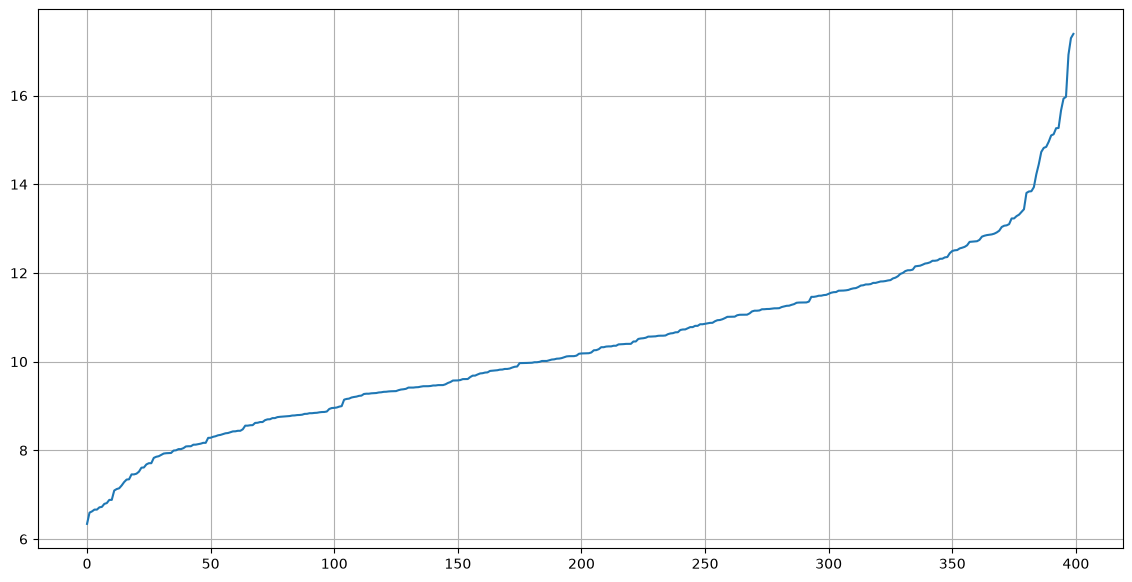

In [15]:
kneighbor = NearestNeighbors(n_neighbors=5)
kneighbor_fit = kneighbor.fit(X)

distance, indices = kneighbor_fit.kneighbors(X)

neighbor = np.sort(distance[:, -1])

plt.figure(figsize=(14, 7))
plt.plot(neighbor)
plt.grid()
plt.show()

In [16]:
dbscan_model = DBSCAN(eps=10.2, min_samples=5)
precise_label = dbscan_model.fit_predict(X)